# HKIA shops by category

This notebook counts the directory entries and listed outlets in each HKIA category. It includes shopping, dining and entertainment. It also compares outlets by restricted-area status.

Place `hkai_shops_en.json` next to this notebook, open it with a Python 3 kernel, and choose **Run All**. If the imports fail, run `%pip install pandas matplotlib` in a notebook cell first.

### 1. Open the JSON file

The file’s `brand` section contains the directory entries. The `kind` section translates category codes into display names.

In [1]:
import json

import pandas as pd
import matplotlib.pyplot as plt

with open("hkai_shops_en.json", encoding="utf-8-sig") as file:
    directory = json.load(file)

### 2. Make a table of all directory entries

A dictionary stores values under unique keys. In this file, each entry has its own key under `brand`, and each listed outlet has its own key under that entry’s `shop`. The loop makes one table row per entry and counts its outlets. `.head()` previews the first five rows.

In [ ]:
rows = []

for shop_id, shop in directory["brand"].items():
    rows.append({
        "shop_id": shop_id,
        "name": shop["name"],
        "section": shop["category"].strip().lower(),
        "category_code": shop.get("cat") or ["(Uncategorised)"],
        "outlets": len(shop.get("shop", {})),
    })

shops = pd.DataFrame(rows)
print(f"{len(shops)} directory entries and {shops['outlets'].sum()} listed outlets")
shops.head()

206 directory entries and 319 listed outlets


### 3. Group by category and count

`explode()` turns a list of categories into one row per category. `drop_duplicates()` ensures that an entry with a repeated category code counts only once in that category. `groupby()` then counts entries and adds up their listed outlets.

An entry and its outlets can appear in several categories. Use the totals above for the overall directory size. All listed outlets are included, regardless of the directory’s active flag.

In [3]:
memberships = shops.explode("category_code")
memberships = memberships.drop_duplicates(["shop_id", "category_code"])

counts = (
    memberships.groupby(["section", "category_code"], as_index=False)
    .agg(directory_entries=("shop_id", "size"), listed_outlets=("outlets", "sum"))
)

labels = []
for section, code in zip(counts["section"], counts["category_code"]):
    labels.append(directory["kind"][section]["cat"].get(code, code))

counts["category"] = labels
counts = counts[["section", "category", "directory_entries", "listed_outlets"]]
counts = counts.sort_values(["section", "directory_entries"], ascending=[True, False])
counts.reset_index(drop=True)

,section,category,directory_entries,listed_outlets
0,dining,"Western Restaurants, Bars & Coffee Shops",24,31
1,dining,Chinese Restaurants & Hong Kong Style Coffee S...,23,23
2,dining,Vegetarian Choices,20,29
3,dining,Fast Food & Food Courts,14,17
4,dining,Dessert,12,13
5,dining,Asian Restaurants,11,12
6,dining,Bakery,6,7
7,dining,Halal,2,2
8,entertainment,Multimedia Zone,5,5
9,entertainment,Themed Zone,4,13


### 4. Plot the counts

Each section gets a horizontal bar chart. A category can have many more outlets than entries when the same brand is listed in several locations.

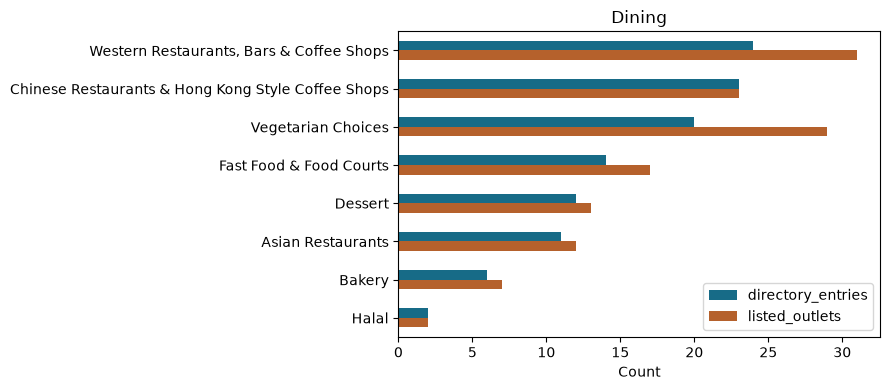

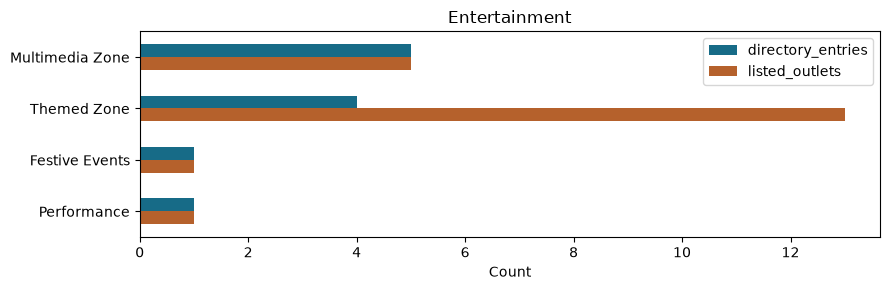

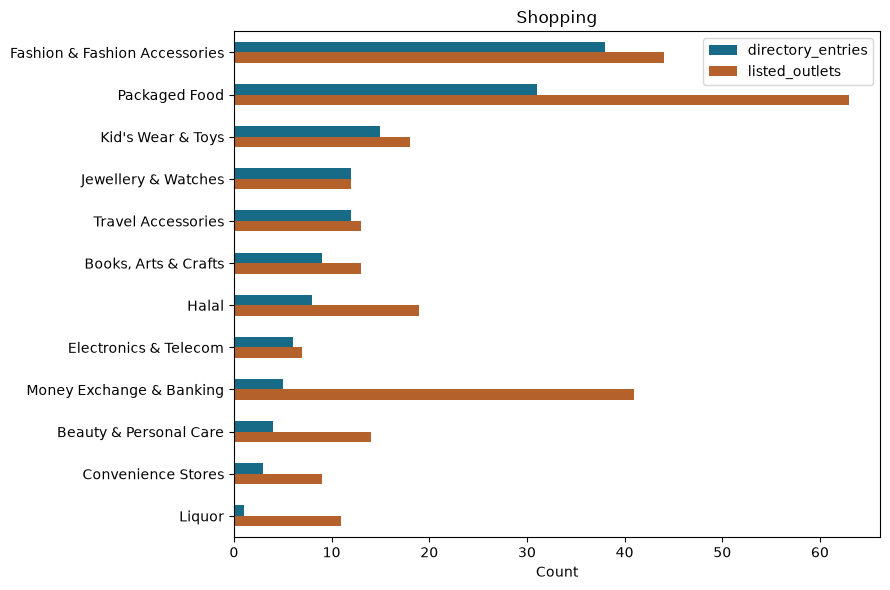

In [4]:
for section, section_counts in counts.groupby("section"):
    ax = section_counts.plot.barh(
        x="category",
        y=["directory_entries", "listed_outlets"],
        color=["#176B87", "#B5612C"],
        title=section.title(),
        figsize=(9, max(3, len(section_counts) * 0.5)),
    )
    ax.invert_yaxis()
    ax.set_xlabel("Count")
    ax.set_ylabel("")
    plt.tight_layout()
    plt.show()

### 5. Compare restricted and non-restricted areas

Each outlet has its own area flag. True means restricted, False means non-restricted, and missing flags are marked Unknown.

The first table counts each outlet once. The second table groups by category and area. An entry with outlets in both areas counts once in each area. An outlet can appear in several categories, so adding category rows can exceed the overall totals.

In [ ]:
from IPython.display import display

area_labels = {True: "Restricted", False: "Non-restricted"}
outlet_rows = []

for shop_id, shop in directory["brand"].items():
    for outlet_id, outlet in shop.get("shop", {}).items():
        area = area_labels.get(outlet.get("restricted"), "Unknown")
        outlet_rows.append((shop_id, outlet_id, area))

outlets = pd.DataFrame(outlet_rows, columns=["shop_id", "outlet_id", "area"])
outlets = outlets.merge(shops[["shop_id", "section"]], on="shop_id")
area_totals = outlets.groupby(["section", "area"]).size().unstack(fill_value=0)
display(area_totals)

# Give each outlet the category codes already assigned to its directory entry.
outlet_categories = outlets.merge(memberships[["shop_id", "category_code"]], on="shop_id")
area_counts = (
    outlet_categories.groupby(["section", "category_code", "area"], as_index=False)
    .agg(directory_entries=("shop_id", "nunique"), listed_outlets=("outlet_id", "size"))
)
area_counts["category"] = [
    directory["kind"][section]["cat"].get(code, code)
    for section, code in zip(area_counts["section"], area_counts["category_code"])
]
display(area_counts[["section", "category", "area", "directory_entries", "listed_outlets"]])

area,Non-restricted,Restricted
section,,
dining,35,45
entertainment,5,15
shopping,51,168


,section,category,area,directory_entries,listed_outlets
0,dining,Asian Restaurants,Non-restricted,3,3
1,dining,Asian Restaurants,Restricted,8,9
2,dining,Bakery,Non-restricted,3,3
3,dining,Bakery,Restricted,4,4
4,dining,Chinese Restaurants & Hong Kong Style Coffee S...,Non-restricted,12,12
5,dining,Chinese Restaurants & Hong Kong Style Coffee S...,Restricted,11,11
6,dining,Dessert,Non-restricted,8,8
7,dining,Dessert,Restricted,4,5
8,dining,Fast Food & Food Courts,Non-restricted,4,5
9,dining,Fast Food & Food Courts,Restricted,11,12


### 6. Plot outlet counts by area

Each chart compares outlet counts side by side for the categories in one section.

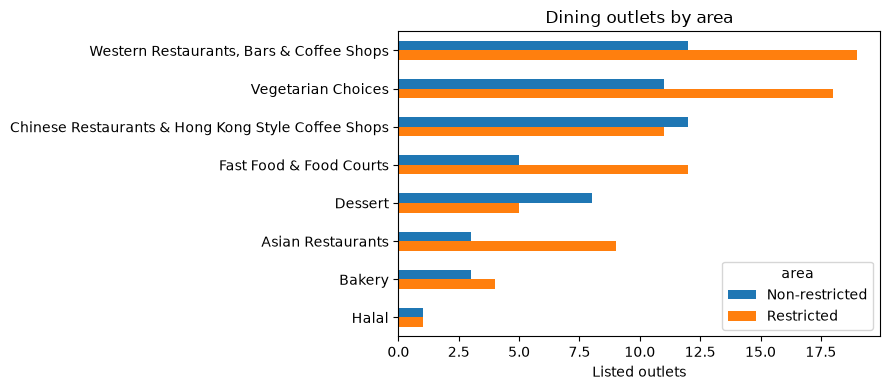

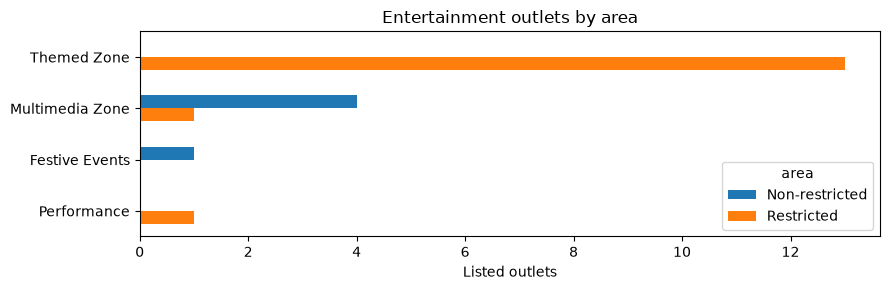

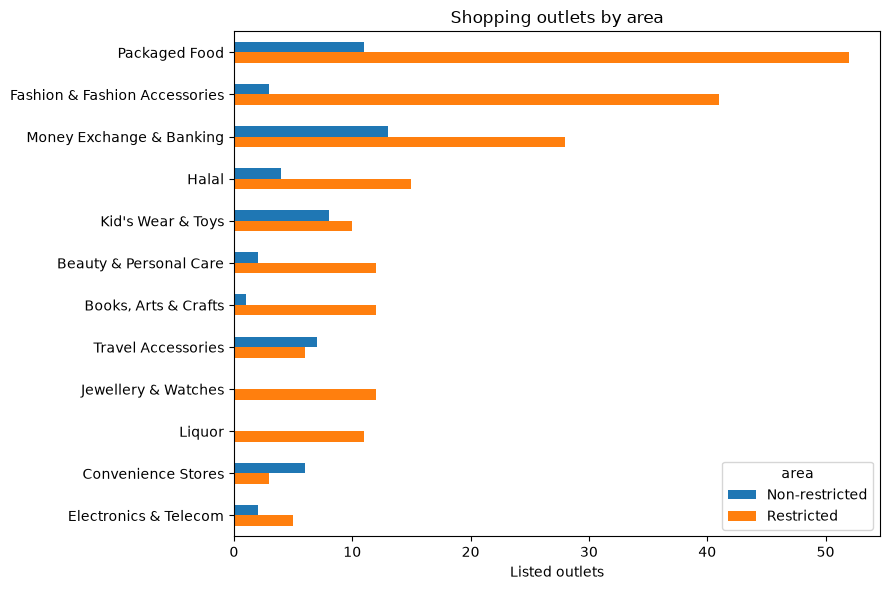

In [6]:
for section, section_counts in area_counts.groupby("section"):
    # Turn the area labels into chart columns and fill missing counts with zero.
    chart = section_counts.pivot(
        index="category", columns="area", values="listed_outlets"
    ).fillna(0)
    order = chart.sum(axis=1).sort_values(ascending=False).index
    ax = chart.loc[order].plot.barh(
        title=f"{section.title()} outlets by area",
        figsize=(9, max(3, len(chart) * 0.5)),
    )
    ax.invert_yaxis()
    ax.set_xlabel("Listed outlets")
    ax.set_ylabel("")
    plt.tight_layout()
    plt.show()